In [5]:
install.packages()

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘colorspace’, ‘diagram’, ‘KernSmooth’, ‘lava’, ‘farver’, ‘labeling’, ‘munsell’, ‘R6’, ‘RColorBrewer’, ‘viridisLite’, ‘pkgconfig’, ‘tzdb’, ‘cpp11’, ‘rpart’, ‘survival’, ‘nnet’, ‘prodlim’, ‘timechange’, ‘stringi’, ‘gtable’, ‘isoband’, ‘MASS’, ‘mgcv’, ‘scales’, ‘tibble’, ‘class’, ‘proxy’, ‘codetools’, ‘iterators’, ‘Rcpp’, ‘dplyr’, ‘clock’, ‘generics’, ‘gower’, ‘hardhat’, ‘ipred’, ‘lubridate’, ‘magrittr’, ‘purrr’, ‘tidyr’, ‘tidyselect’, ‘timeDate’, ‘stringr’, ‘ggplot2’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘nlme’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’, ‘withr’




In [48]:
library("PRROC")
library("data.table")
library("xgboost")
library("caret")
library("ggplot2")

NULL


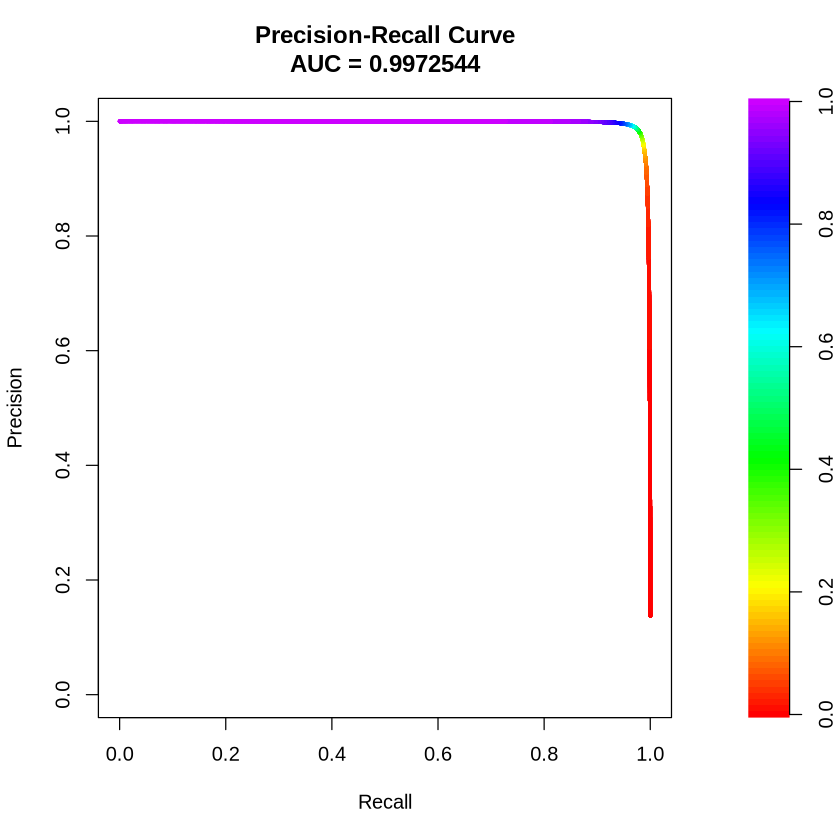

In [9]:
# 一个小测试 dtm.txt是旧的没有完整FA的数据
dtm <- fread("dtm.txt", sep="\t")
best_model_240805 <- xgb.load("best_model_240805")

features = c("DP","ECNT","MBQ_REF","MBQ_ALT","MFRL_REF","MFRL_ALT","MMQ_REF","MMQ_ALT","MPOS","NALOD","NLOD","TLOD",
             "avg_mapping_quality","avg_basequality","avg_pos_as_fraction","avg_num_mismatches_as_fraction","avg_sum_mismatch_qualities")

predictions <- predict(best_model_240805, newdata=data.matrix(dtm[, features, with=FALSE]), type = "prob")

pr_curve <- pr.curve(scores.class0 = predictions, weights.class0 = dtm$label,curve=T)

pr_auc <- pr_curve$auc

print(pr_auc)

# 绘制PR曲线
plot(pr_curve, main = "Precision-Recall Curve", xlab = "Recall", ylab = "Precision")

In [77]:
dtm <- fread("dtm_0819.txt", sep="\t")

max_depths <- c(3, 5, 7, 9)
etas <- c(0.01, 0.05, 0.1, 0.2)
nrounds_list <- c(100, 200, 400)

results <- data.table(max_depth = integer(), eta = numeric(), nrounds = integer(), k = integer(), pr_auc = numeric())

for (max_depth in max_depths) {
  for (eta in etas) {
    for (nrounds in nrounds_list) {
        
    k <- 5
    folds <- createFolds(dtm$label, k = k, list = TRUE)
      
      for (i in 1:k) {
        # 划分训练集和验证集
        train_indices <- folds[[i]]
        dt_train <- dtm[-train_indices]
        dt_test <- dtm[train_indices]
        
        # 准备训练数据
        dtrain <- xgb.DMatrix(data = data.matrix(dt_train[, features, with=FALSE]), label = dt_train$label)
        
        # 训练 xgboost 模型
        xgb_model <- xgboost(
          data = dtrain, 
          max.depth = max_depth, 
          eta = eta, 
          nthread = 150, 
          nrounds = nrounds,
          objective = "binary:logistic", 
          verbose = FALSE
        )

          predictions <- predict(xgb_model, newdata=data.matrix(dt_test[, features, with=FALSE]), type = "prob")

          pr_curve <- pr.curve(scores.class0 = predictions, weights.class0 = dt_test$label,curve=T)
          pr_auc <- pr_curve$auc.integral
        print(data.table(max_depth = max_depth, eta = eta, nrounds = nrounds, k = i, pr_auc = pr_auc))
          results <- rbind(results, data.table(max_depth = max_depth, eta = eta, nrounds = nrounds, k = i, pr_auc = pr_auc))
      }
      
      
      }
  }
}

best_params <- results[which.max(pr_auc)]
print(best_params)

   max_depth   eta nrounds     k    pr_auc
       <num> <num>   <num> <int>     <num>
1:         3  0.01     100     1 0.9519029
   max_depth   eta nrounds     k   pr_auc
       <num> <num>   <num> <int>    <num>
1:         3  0.01     100     2 0.951441
   max_depth   eta nrounds     k    pr_auc
       <num> <num>   <num> <int>     <num>
1:         3  0.01     100     3 0.9567725
   max_depth   eta nrounds     k    pr_auc
       <num> <num>   <num> <int>     <num>
1:         3  0.01     100     4 0.9519582
   max_depth   eta nrounds     k    pr_auc
       <num> <num>   <num> <int>     <num>
1:         3  0.01     100     5 0.9570421
   max_depth   eta nrounds     k    pr_auc
       <num> <num>   <num> <int>     <num>
1:         3  0.01     200     1 0.9669793
   max_depth   eta nrounds     k    pr_auc
       <num> <num>   <num> <int>     <num>
1:         3  0.01     200     2 0.9637682
   max_depth   eta nrounds     k    pr_auc
       <num> <num>   <num> <int>     <num>
1:         3  

In [85]:
dim(dtm)

[1] 493937     27

In [80]:
fwrite(results, "results_0820.xls", sep="\t")

In [94]:
med_auc <- results[, .(med = median(pr_auc)), by = c("max_depth", "eta", "nrounds")]

In [95]:
med_auc

max_depth,eta,nrounds,med
<dbl>,<dbl>,<dbl>,<dbl>
3,0.01,100,0.9519582
3,0.01,200,0.9645042
3,0.01,400,0.9758858
3,0.05,100,0.9788225
3,0.05,200,0.9836354
3,0.05,400,0.9874698
3,0.10,100,0.9834776
3,0.10,200,0.9869133
3,0.10,400,0.9890963


In [97]:
fwrite(med_auc,"med_auc_0820.xls", sep="\t")